In [72]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from UnifacDortmund import UnifacDortmund
from PhaseCalculation import CalculateComps as cc

In [2]:
group_contribution = pl.read_csv("SensitivityAnalysis/sensitivity_group_contribution.csv")
MW = pl.read_csv("SensitivityAnalysis/sensitivity_MW.csv")
coeffs = pl.read_csv("SensitivityAnalysis/sensitivity_params.csv")

In [3]:
group_contribution

FAME/FAEE,GLYCEROL,ALCOHOL,OIL,DAG,MAG,ACID,H2O,Group,Stat
f64,f64,f64,f64,f64,f64,f64,f64,str,str
0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,"""Coconut""","""min"""
10.499156,2.0,0.0,33.497469,22.998313,12.499156,10.499156,0.0,"""Coconut""","""min"""
2.0,0.0,1.0,3.0,2.0,1.0,1.0,0.0,"""Coconut""","""min"""
0.119954,0.0,0.0,0.359862,0.239908,0.119954,0.119954,0.0,"""Coconut""","""min"""
0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,"""Coconut""","""min"""
…,…,…,…,…,…,…,…,…,…
1.06632,0.0,0.0,3.198959,2.132639,1.06632,1.06632,0.0,"""Peanut""","""mean"""
0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,"""Peanut""","""mean"""
1.0,0.0,0.0,3.0,2.0,1.0,0.0,0.0,"""Peanut""","""mean"""


In [4]:
MW

group,stat,MW_FAME/FAEE,MW_Glycerol,MW_Alcohol,MW_Oil,MW_DAG,MW_MAG,MW_FA,MW_H2O
str,str,f64,f64,f64,f64,f64,f64,f64,i64
"""Grape Seed""","""mean""",307.073169,92.09,32.04,917.219508,625.146338,333.073169,279.073169,18
"""Rapeseed""","""mean""",305.837765,92.09,32.04,913.513295,622.67553,331.837765,277.837765,18
"""Chicha""","""mean""",305.611285,92.09,32.04,912.833854,622.222569,331.611285,277.611285,18
"""Triolein""","""mean""",310.0,92.09,32.04,926.0,631.0,336.0,282.0,18
"""Linseed""","""mean""",305.816573,92.09,32.04,913.449718,622.633145,331.816573,277.816573,18
…,…,…,…,…,…,…,…,…,…
"""Rice Bran""","""mean""",303.813132,92.09,32.04,907.439397,618.626265,329.813132,275.813132,18
"""Jatropha""","""min""",302.688776,92.09,32.04,904.066329,616.377552,328.688776,274.688776,18
"""Jatropha""","""median""",305.268101,92.09,32.04,911.804304,621.536203,331.268101,277.268101,18


In [5]:
coeffs

group,stat,m,n,p,b
str,str,f64,f64,f64,i64
"""Grape Seed""","""mean""",12.773231,1.547998,0.0,0
"""Rapeseed""","""mean""",13.133518,1.306481,0.0,0
"""Chicha""","""mean""",14.352474,0.641409,0.0,0
"""Triolein""","""mean""",14.0,1.0,0.0,0
"""Linseed""","""mean""",11.78236,2.033213,0.0,0
…,…,…,…,…,…
"""Rice Bran""","""mean""",13.28067,1.149375,0.0,0
"""Jatropha""","""min""",13.172086,1.164599,0.0,0
"""Jatropha""","""median""",13.249312,1.222221,0.0,0


#### 1. Parametros UNIFAC Dortmund

In [6]:
params = np.loadtxt(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\UDortmundParamsGARun1.out")

In [13]:
params
A = params[0:30]
B = params[30:60]
C = params[60:90]
    
GIP = cc.define_GIP(A, B, C)

thermo_model = UnifacDortmund

#### 2. Biodiesel, Glycerol, Alcohol

In [112]:
global_comps = np.array([0.80, 0.1, 0.1, 0, 0, 0, 0, 0]).reshape(1, 8)
T = np.linspace(283.15, 353.15, 50)
groups = group_contribution.group_by(["Group", "Stat"])
groups_MW = group_contribution.group_by(["group", "stat"])

In [113]:

def analysis_one(global_comps, MW, v, T):
    
    return (cc.calculate_comps(data=global_comps, v=v, data_MW=MW, 
                         temperature=T, thermo_model=thermo_model, GIP=GIP))

In [114]:
results_list = []
comp_list = []

for name, data in groups:

    MW_loop = MW.filter(
        (pl.col("group") == name[0]) & (pl.col("stat") == name[1])
    ) 
    
    data = data.drop(["Group", "Stat"]).to_numpy()
    MW_loop = MW_loop.drop(["group", "stat"]).to_numpy().reshape(8)
    comp_list.append(name[0])
     
    for temperature in T:
       comps = analysis_one(global_comps, MW_loop, data, temperature) 
       comps = np.append(comps, temperature)
       comps = np.append(comps, MW_loop[0])
       results_list.append(comps)
       
       

results_total = np.vstack(results_list) 




c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


In [115]:
results_total
filtered_results = results_total[results_total[:, 0] != 0.80]

In [116]:
filtered_results

array([[9.99997369e-01, 5.00002761e-07, 2.17270016e-06, ...,
        0.00000000e+00, 2.83150000e+02, 3.05566587e+02],
       [9.99997368e-01, 5.00002764e-07, 2.17418420e-06, ...,
        0.00000000e+00, 2.84578571e+02, 3.05566587e+02],
       [9.99997369e-01, 5.00002761e-07, 2.17268175e-06, ...,
        0.00000000e+00, 2.86007143e+02, 3.05566587e+02],
       ...,
       [9.99997581e-01, 5.00002338e-07, 1.96091120e-06, ...,
        0.00000000e+00, 3.50292857e+02, 3.23771959e+02],
       [9.99997581e-01, 5.00002338e-07, 1.96095468e-06, ...,
        0.00000000e+00, 3.51721429e+02, 3.23771959e+02],
       [9.99997581e-01, 5.00002338e-07, 1.96091350e-06, ...,
        0.00000000e+00, 3.53150000e+02, 3.23771959e+02]], shape=(4900, 18))

In [117]:
FAME_comp = filtered_results[:,0]
FAME_MW = filtered_results[:,-1]
T = filtered_results[:,-2]


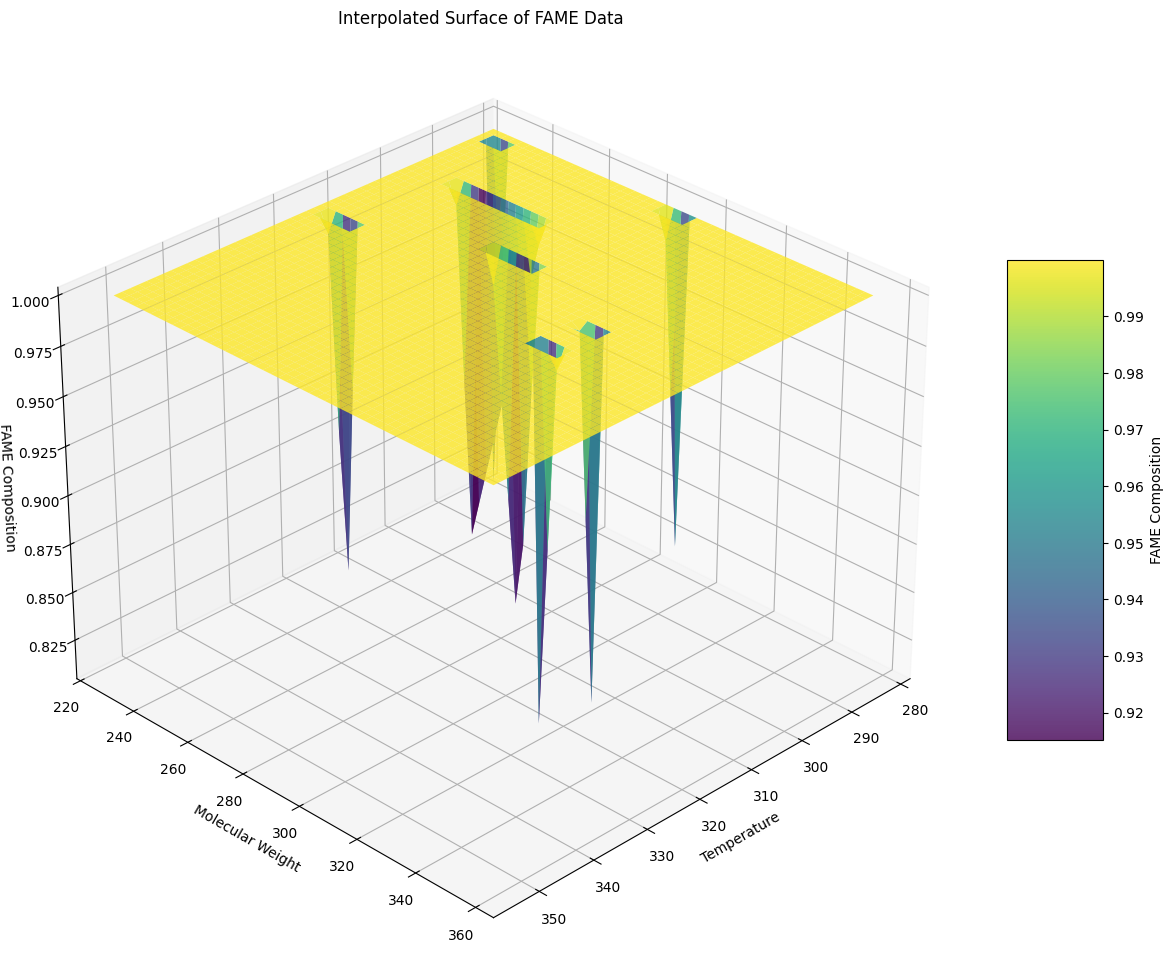

In [118]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

# Your existing arrays
# FAME_comp = results_total[:,0]
# FAME_MW = results_total[:,-1]
# T = results_total[:,-2]

# Create a grid for interpolation
T_grid = np.linspace(min(T), max(T), 50)
MW_grid = np.linspace(min(FAME_MW), max(FAME_MW), 50)
T_mesh, MW_mesh = np.meshgrid(T_grid, MW_grid)

# Interpolate FAME_comp values onto the grid
points = np.column_stack((T, FAME_MW))
FAME_comp_grid = griddata(points, FAME_comp, (T_mesh, MW_mesh), method='linear')

# Create a new figure
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Create surface plot
surf = ax.plot_surface(T_mesh, MW_mesh, FAME_comp_grid, 
                     cmap='viridis', 
                     edgecolor='none', 
                     alpha=0.8)


# Add a color bar
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='FAME Composition')

# Add labels with your requested arrangement
ax.set_xlabel('Temperature')
ax.set_ylabel('Molecular Weight')
ax.set_zlabel('FAME Composition')
ax.set_title('Interpolated Surface of FAME Data')

# Adjust the viewing angle for better visualization
ax.view_init(elev=30, azim=45)

plt.tight_layout()
plt.show()